# 08 — Distilling the transformer backbones (round 6): does the round-4 result replicate?

Round 4 showed that out-of-fold ensemble distillation improves ConvNeXt-S, ResNet-50 and EfficientNetV2-S on every fold.
Round 6 applies the **identical, pre-registered protocol** (`research/round6_plan.md`) to the two transformers:
DINOv2 ViT-B/14 and ViT-B/16. Same soft labels (`results/soft_labels/bb5_calib_oof.csv`), loss 0.5·CE(hard) + 0.5·CE(soft),
448 px, 30 epochs, their round-3 learning rate (5e-5), TTA-20 and logit adjustment. Students are judged on the **test set**
against their hard-label twins (student CV is optimistic: the teacher saw the CV fold).

**Reproduce:** `salloc ... srun ... bash slurm/run_jobs_node.sh slurm/jobs/round6_train.txt slurm/jobs/round6_eval.txt` (~85 min),
then `python research/round6_analysis.py`.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HWX_DIR = Path.cwd() if (Path.cwd() / "isic").is_dir() else Path.cwd().parent
sys.path.insert(0, str(HWX_DIR))
from isic import analysis as A
from isic.data import CLASSES

pd.set_option("display.width", 200)
RUN_TRAINING = False   # True on a GPU node: re-create one DINOv2 student fold (~31 min)

def run(cmd):
    print("$", cmd, flush=True)
    subprocess.run(cmd, shell=True, check=True, cwd=HWX_DIR)

if RUN_TRAINING:
    run("python train_classifier.py --run-name dinov2_b14_kd_res448 --model vit_base_patch14_dinov2.lvd142m --lr 5e-5 --img-size 448 "
        "--soft-labels results/soft_labels/bb5_calib_oof.csv --kd-alpha 0.5 --fold 0")
    run("python evaluate_tta.py dinov2_b14_kd_res448 --crops 5 --folds 0")
    run("python posthoc_logit_adjustment.py dinov2_b14_kd_res448_tta20")

## 1. Students vs hard-label twins, all five architectures (official test, paired over folds)

In [2]:
PAIRS = [("ConvNeXt-S", "convnext_s_res448_tta20_la", "convnext_s_kd_res448_tta20_la", 4),
         ("ResNet-50", "resnet50_ce_res448_tta20_la", "resnet50_kd_res448_tta20_la", 4),
         ("EfficientNetV2-S", "effv2_s_res448_tta20_la", "effv2_s_kd_res448_tta20_la", 4),
         ("DINOv2 ViT-B/14", "dinov2_b14_res448_tta20_la", "dinov2_b14_kd_res448_tta20_la", 6),
         ("ViT-B/16", "vit_b16_res448_tta20_la", "vit_b16_kd_res448_tta20_la", 6)]
rows, diffs = [], []
for name, h, k, rnd in PAIRS:
    hb, kb = A.per_fold(h).bal_acc, A.per_fold(k).bal_acc
    diffs += list(kb.values - hb.values)
    rows.append({"architecture": name, "round": rnd, "hard": hb.mean(), "distilled": kb.mean(), "test AUC (distilled)": A.per_fold(k).auc.mean()})
display(pd.DataFrame(rows).set_index("architecture").round(4))
d = np.array(diffs)
print(f"pooled over {len(d)} fold pairs: mean gain {d.mean():+.4f}, improved in {(d > 0).sum()}/{len(d)}; "
      f"sign test p = {0.5 ** len(d):.1e} (pairs share one teacher, so read this as a sanity check, not an exact p-value)")
pd.concat([A.paired_table([k], h, names=[name], splits=("official_test",), metrics=("balanced_acc", "macro_auc", "mel_sensitivity", "macro_f1"))
           for name, h, k, _ in PAIRS])

,round,hard,distilled,test AUC (distilled)
architecture,,,,
ConvNeXt-S,4,0.8170,0.8639,0.9826
ResNet-50,4,0.8346,0.8543,0.9792
EfficientNetV2-S,4,0.8324,0.8508,0.9812
DINOv2 ViT-B/14,6,0.8252,0.8632,0.9834
ViT-B/16,6,0.8024,0.8442,0.9826


pooled over 25 fold pairs: mean gain +0.0330, improved in 25/25; sign test p = 3.0e-08 (pairs share one teacher, so read this as a sanity check, not an exact p-value)


,test_bal_acc,test_auc,test_mel_sens,test_f1
ConvNeXt-S,+0.047 ± 0.020 (5/5),+0.006 ± 0.002 (5/5),+0.048 ± 0.035 (5/5),+0.037 ± 0.033 (4/5)
ResNet-50,+0.020 ± 0.011 (5/5),+0.006 ± 0.003 (5/5),+0.035 ± 0.031 (5/5),+0.030 ± 0.032 (4/5)
EfficientNetV2-S,+0.018 ± 0.005 (5/5),+0.004 ± 0.001 (5/5),+0.046 ± 0.044 (4/5),+0.010 ± 0.008 (4/5)
DINOv2 ViT-B/14,+0.038 ± 0.023 (5/5),+0.009 ± 0.007 (5/5),-0.001 ± 0.057 (2/5),+0.040 ± 0.066 (3/5)
ViT-B/16,+0.042 ± 0.014 (5/5),+0.009 ± 0.004 (5/5),+0.070 ± 0.075 (4/5),+0.054 ± 0.038 (4/5)


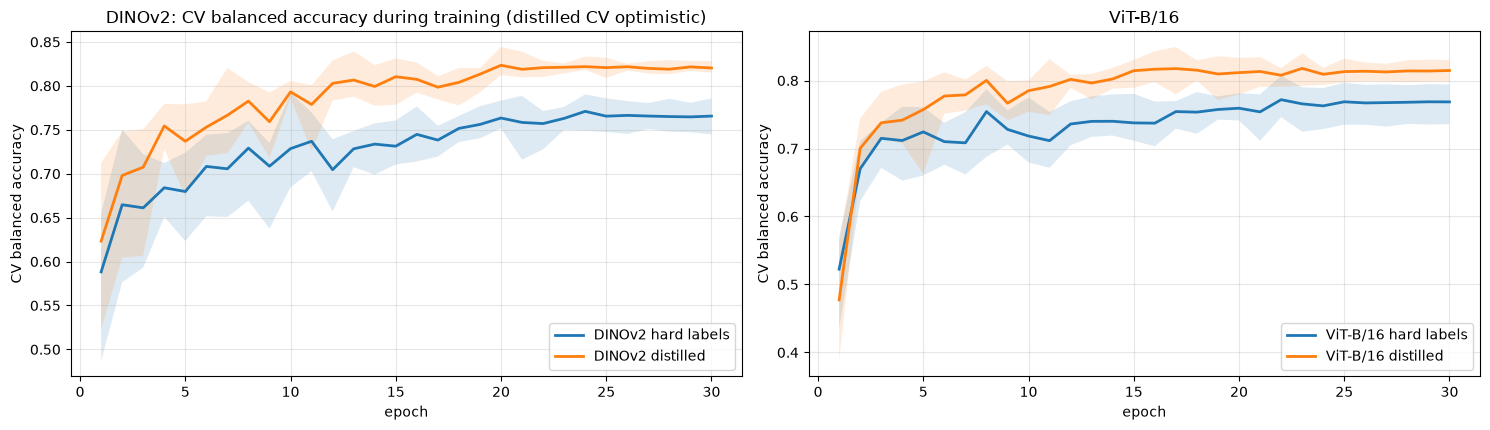

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
A.plot_curves(axes[0], ["dinov2_b14_res448", "dinov2_b14_kd_res448"], ["DINOv2 hard labels", "DINOv2 distilled"])
axes[0].set_title("DINOv2: CV balanced accuracy during training (distilled CV optimistic)")
A.plot_curves(axes[1], ["vit_b16_res448", "vit_b16_kd_res448"], ["ViT-B/16 hard labels", "ViT-B/16 distilled"])
axes[1].set_title("ViT-B/16")
plt.tight_layout()

## 2. Ensembles with all five students (reported only; the official final model stays the round-4 pre-registered one)

In [4]:
def all_models(run):
    ps = [pd.read_csv(A.RESULTS / run / f"fold{k}" / "pred_official_test.csv") for k in range(5)]
    return ps[0]["label"].map(CLASSES.index).to_numpy(), np.mean([p[CLASSES].to_numpy() for p in ps], 0).argmax(1)
def bacc(y, p): return np.mean([(p[y == c] == c).mean() for c in range(7)])
y0, _ = all_models("dl_final8_calib_tau"); rng = np.random.default_rng(0)
B = [np.concatenate([rng.choice(np.where(y0 == c)[0], (y0 == c).sum()) for c in range(7)]) for _ in range(2000)]
rows = []
for label, run in [("5 backbones (round 3)", "ens5_res448_tta20_la"), ("final, pre-registered (5 bb + 3 students)", "dl_final8_calib_tau"),
                   ("5 students", "dl_kd5_calib_tau"), ("5 backbones + 5 students", "dl_bb5kd5_calib_tau")]:
    _, p = all_models(run); bs = np.array([bacc(y0[b], p[b]) for b in B])
    rows.append({"ensemble": label, "test per fold": A.per_fold(run).bal_acc.mean(), "test all models": bacc(y0, p),
                 "95% CI low": np.percentile(bs, 2.5), "95% CI high": np.percentile(bs, 97.5)})
pd.DataFrame(rows).set_index("ensemble").round(4)

,test per fold,test all models,95% CI low,95% CI high
ensemble,,,,
5 backbones (round 3),0.8766,0.8923,0.8678,0.9158
"final, pre-registered (5 bb + 3 students)",0.8829,0.8882,0.8622,0.9129
5 students,0.8751,0.8848,0.8596,0.9085
5 backbones + 5 students,0.8840,0.8934,0.8694,0.9156


## Takeaways
* **The result replicates.** DINOv2 +0.038 and ViT-B/16 +0.042 test balanced accuracy over their hard-label twins, both on
  5/5 folds, with AUC up on every fold. Across the five architectures distillation wins on **25 of 25 fold pairs** (+0.033 on
  average). The transformers, which were weakest on hard labels, gain the most.
* DINOv2's melanoma sensitivity does not rise with distillation (−0.001, 2/5 folds), unlike the other four architectures.
* Ensembles do not change the picture: all five students together with the five backbones reach 0.893 on test (CI 0.869–0.916),
  within noise of the round-3 ensemble (0.892) and the pre-registered final model (0.888). Distillation makes **single networks**
  much better; it does not add ensemble diversity.